In [1]:
!pip install -q -U kaggle


In [2]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
print("Token loaded:", bool(os.environ["KAGGLE_API_TOKEN"]))

Token loaded: True


In [3]:
!mkdir -p /content/data
!kaggle datasets download -d vipoooool/new-plant-diseases-dataset -p /content/data

Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
100% 2.70G/2.70G [00:27<00:00, 104MB/s]



In [4]:
!unzip -q /content/data/new-plant-diseases-dataset.zip -d /content/data/plant_disease
!rm /content/data/new-plant-diseases-dataset.zip

In [5]:
import os

def show_tree(root, max_depth=3):
    root_depth = root.rstrip("/").count("/")
    for dirpath, dirnames, _ in os.walk(root):
        depth = dirpath.count("/") - root_depth
        if depth >= max_depth:
            dirnames[:] = []
            continue
        print("  " * depth + os.path.basename(dirpath) + "/")

show_tree("/content/data/plant_disease", max_depth=3)

plant_disease/
  new plant diseases dataset(augmented)/
    New Plant Diseases Dataset(Augmented)/
  test/
    test/
  New Plant Diseases Dataset(Augmented)/
    New Plant Diseases Dataset(Augmented)/


In [6]:
show_tree("/content/data/plant_disease", max_depth=5)


plant_disease/
  new plant diseases dataset(augmented)/
    New Plant Diseases Dataset(Augmented)/
      train/
        Corn_(maize)___healthy/
        Tomato___Tomato_Yellow_Leaf_Curl_Virus/
        Tomato___Tomato_mosaic_virus/
        Apple___healthy/
        Apple___Cedar_apple_rust/
        Orange___Haunglongbing_(Citrus_greening)/
        Pepper,_bell___Bacterial_spot/
        Peach___healthy/
        Corn_(maize)___Common_rust_/
        Grape___Black_rot/
        Peach___Bacterial_spot/
        Raspberry___healthy/
        Blueberry___healthy/
        Tomato___Early_blight/
        Tomato___healthy/
        Grape___Esca_(Black_Measles)/
        Cherry_(including_sour)___healthy/
        Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot/
        Strawberry___healthy/
        Tomato___Bacterial_spot/
        Soybean___healthy/
        Cherry_(including_sour)___Powdery_mildew/
        Potato___Late_blight/
        Tomato___Leaf_Mold/
        Potato___healthy/
        Strawberry___

In [7]:
import os

base = "/content/data/plant_disease/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)"
train_dir = os.path.join(base, "train")
valid_dir = os.path.join(base, "valid")

def count_images(folder):
    return sum(len(files) for _, _, files in os.walk(folder))

print("Train classes:", len(os.listdir(train_dir)), "| images:", count_images(train_dir))
print("Valid classes:", len(os.listdir(valid_dir)), "| images:", count_images(valid_dir))

Train classes: 38 | images: 70295
Valid classes: 38 | images: 17572


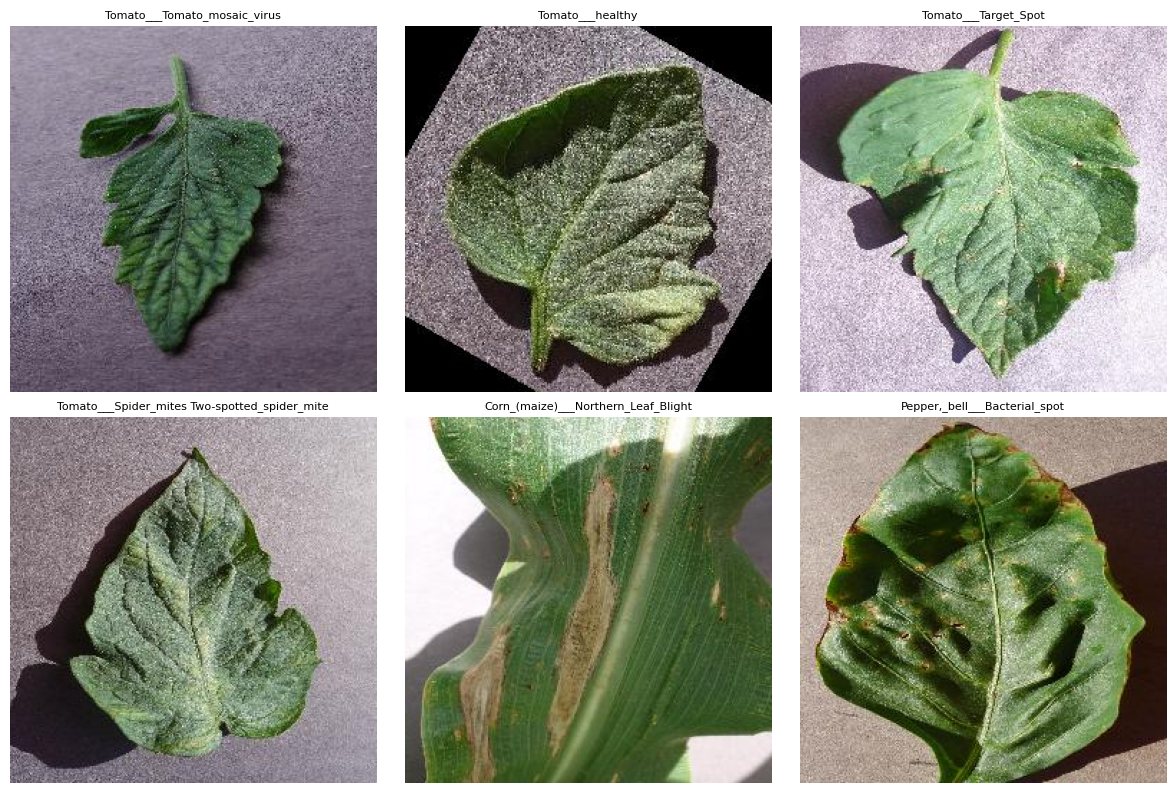

In [8]:
import random
import matplotlib.pyplot as plt
from PIL import Image

classes = random.sample(os.listdir(train_dir), 6)

plt.figure(figsize=(12, 8))
for i, cls in enumerate(classes):
    folder = os.path.join(train_dir, cls)
    img_path = os.path.join(folder, random.choice(os.listdir(folder)))
    plt.subplot(2, 3, i + 1)
    plt.imshow(Image.open(img_path))
    plt.title(cls, fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [9]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=True)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    valid_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False)

class_names = train_ds.class_names
print("Number of classes:", len(class_names))
print(class_names[:5])

Found 70295 files belonging to 38 classes.
Found 17572 files belonging to 38 classes.
Number of classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']


In [10]:
import tensorflow as tf
print("GPUs found:", tf.config.list_physical_devices("GPU"))


GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [11]:
from tensorflow.keras import layers, Model

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base_model.trainable = False  # freeze: keep its existing knowledge

inputs = tf.keras.Input(shape=(224, 224, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = Model(inputs, outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [12]:
history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=3
)

Epoch 1/3
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 166s 64ms/step - accuracy: 0.8886 - loss: 0.3967 - val_accuracy: 0.9414 - val_loss: 0.1896
Epoch 2/3
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 140s 46ms/step - accuracy: 0.9439 - loss: 0.1727 - val_accuracy: 0.9543 - val_loss: 0.1437
Epoch 3/3
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 94s 43ms/step - accuracy: 0.9536 - loss: 0.1421 - val_accuracy: 0.9553 - val_loss: 0.1370


In [13]:
import json
from google.colab import files

model.save("plant_disease_model.keras")

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

files.download("plant_disease_model.keras")
files.download("class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

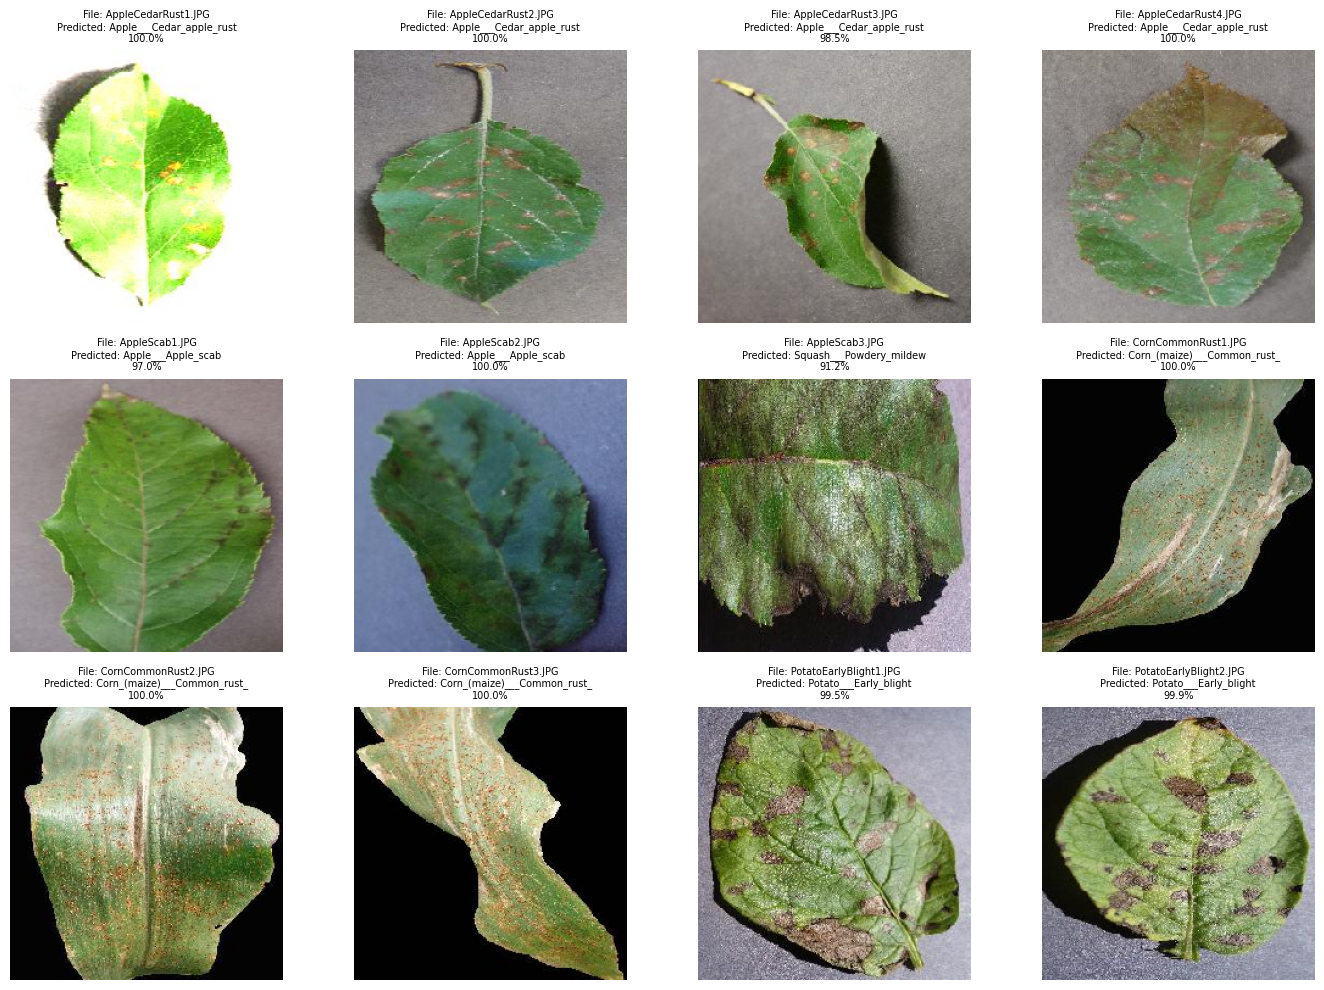

In [14]:
import numpy as np
import matplotlib.pyplot as plt

test_dir = "/content/data/plant_disease/test/test"
test_files = sorted(os.listdir(test_dir))[:12]

plt.figure(figsize=(14, 10))
for i, fname in enumerate(test_files):
    img = tf.keras.utils.load_img(os.path.join(test_dir, fname), target_size=(224, 224))
    arr = np.expand_dims(tf.keras.utils.img_to_array(img), axis=0)
    probs = model.predict(arr, verbose=0)[0]
    pred = class_names[int(np.argmax(probs))]
    conf = float(np.max(probs)) * 100

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f"File: {fname}\nPredicted: {pred}\n{conf:.1f}%", fontsize=7)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [15]:
test_files = sorted(os.listdir(test_dir))

for fname in test_files:
    img = tf.keras.utils.load_img(os.path.join(test_dir, fname), target_size=(224, 224))
    arr = np.expand_dims(tf.keras.utils.img_to_array(img), axis=0)
    probs = model.predict(arr, verbose=0)[0]
    pred = class_names[int(np.argmax(probs))]
    conf = float(np.max(probs)) * 100
    print(f"{fname:35s} -> {pred:55s} {conf:5.1f}%")

print("\nTotal test images:", len(test_files))

AppleCedarRust1.JPG                 -> Apple___Cedar_apple_rust                                100.0%
AppleCedarRust2.JPG                 -> Apple___Cedar_apple_rust                                100.0%
AppleCedarRust3.JPG                 -> Apple___Cedar_apple_rust                                 98.5%
AppleCedarRust4.JPG                 -> Apple___Cedar_apple_rust                                100.0%
AppleScab1.JPG                      -> Apple___Apple_scab                                       97.0%
AppleScab2.JPG                      -> Apple___Apple_scab                                      100.0%
AppleScab3.JPG                      -> Squash___Powdery_mildew                                  91.2%
CornCommonRust1.JPG                 -> Corn_(maize)___Common_rust_                             100.0%
CornCommonRust2.JPG                 -> Corn_(maize)___Common_rust_                             100.0%
CornCommonRust3.JPG                 -> Corn_(maize)___Common_rust_                

In [18]:
!pip install -q gradio

import json
import numpy as np
import tensorflow as tf
import gradio as gr
from google.colab import files

files.upload()  # select BOTH files: plant_disease_model.keras and class_names.json

model = tf.keras.models.load_model("plant_disease_model.keras")
with open("class_names.json") as f:
    class_names = json.load(f)

def predict(image):
    img = tf.image.resize(image, (224, 224))
    arr = np.expand_dims(img.numpy(), axis=0)
    probs = model.predict(arr, verbose=0)[0]
    best = int(np.argmax(probs))

    crop, condition = class_names[best].split("___")
    crop = crop.replace("_", " ")
    condition = condition.replace("_", " ").strip()
    conf = float(probs[best]) * 100

    if condition.lower() == "healthy":
        verdict = f"HEALTHY: this {crop} leaf looks healthy."
    else:
        verdict = f"DISEASED: {crop} leaf, {condition}."

    note = "\nNot sure, please retake the photo on a plain background." if conf < 70 else ""
    return f"{verdict}\nConfidence: {conf:.1f}%{note}"

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(label="Upload a leaf photo"),
    outputs=gr.Textbox(label="Result"),
    title="Plant Disease Detector",
    description="Upload a photo of a single leaf on a plain background."
)

demo.launch(share=True)


Saving m.jpg to m (1).jpg
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ffd7c0dd1585bb6aa5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
